TODO:

- [x] download the data
- [ ] read the hugging face tutorials
- [ ] reproduce the results of the tutorial
- [ ] create a baseline model?

In [1]:
# Make sure you called the prepare_dataset.py script before running this one

from datasets import load_dataset
dataset = load_dataset("imagefolder", data_dir="dl_action_dataset")

/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Resolving data files: 100%|██████████| 534/534 [00:00<00:00, 1263259.07it/s]
Generating train split: 2464 examples [00:00, 23186.52 examples/s]
Generating validation split: 526 examples [00:00, 30312.91 examples/s]
Generating test split: 534 examples [00:00, 16298.99 examples/s]


In [2]:
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 2464
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 526
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 534
    })
})

In [3]:
print("Available classes:", *dataset["train"].features["label"].names)

Available classes: cut pour slide stir stir1


Filter: 100%|██████████| 2464/2464 [00:08<00:00, 283.33 examples/s]


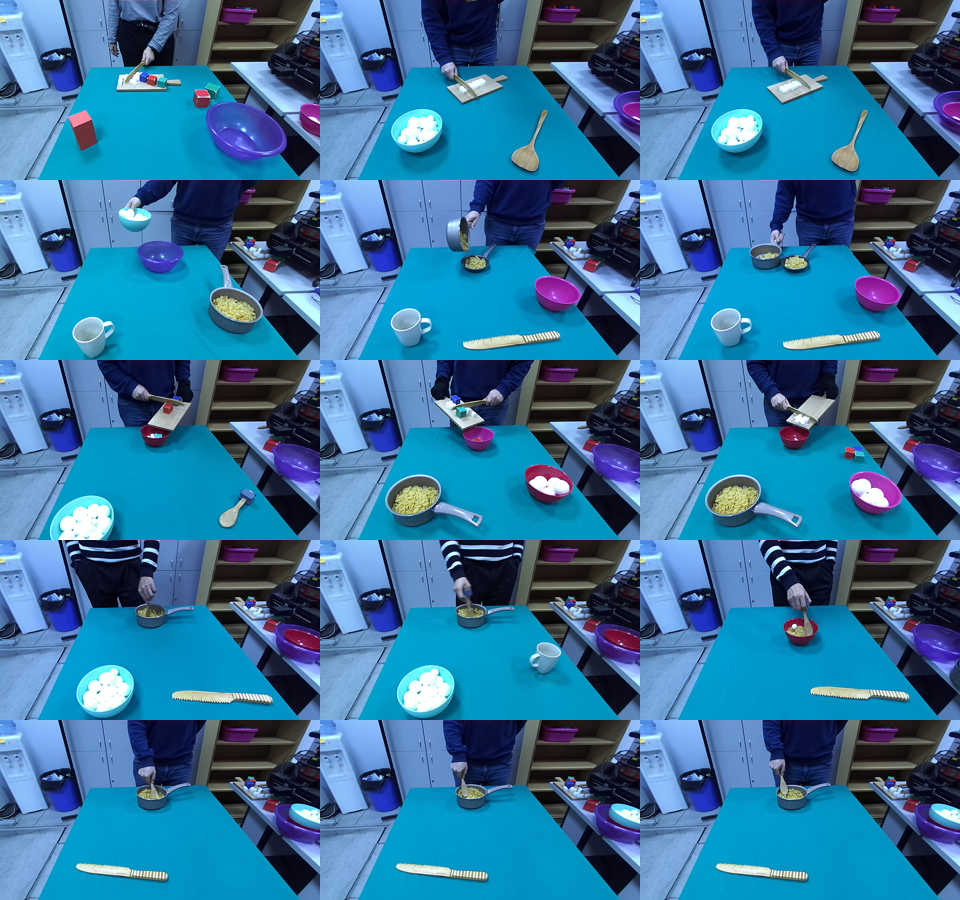

In [4]:
from PIL import ImageDraw, Image
import numpy as np

# Borrowed and modified from https://huggingface.co/blog/fine-tune-vit 
def show_examples(ds, examples_per_class):

    h, w, _ = np.array(dataset['train'][10]["image"]).shape
    h, w = h // 2, w // 2
    size = (w, h)
    
    labels = ds['train'].features['label'].names
    grid = Image.new('RGB', size=(examples_per_class * w, len(labels) * h))
    draw = ImageDraw.Draw(grid)

    for label_id, label in enumerate(labels):

        # Filter the dataset by a single label, shuffle it, and grab a few samples
        ds_slice = ds['train'].filter(lambda ex: ex['label'] == label_id, ).shuffle().select(range(examples_per_class))

        # Plot this label's examples along a row
        for i, example in enumerate(ds_slice):
            image = example['image']
            idx = examples_per_class * label_id + i
            box = (idx % examples_per_class * w, idx // examples_per_class * h)
            grid.paste(image.resize(size), box=box)

    return grid

show_examples(dataset, examples_per_class=3)


In [5]:
labels = dataset["train"].features["label"].names
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = i
    id2label[i] = label

In [6]:
# The pretrained ViT model:
model_name = 'google/vit-base-patch16-224-in21k'


In [7]:
# Preprocess the images (just normalization)

from transformers import ViTImageProcessor # type: ignore


processor = ViTImageProcessor.from_pretrained(model_name)

def transform(example_batch):
    # Take a list of PIL images and turn them to pixel values
    inputs = processor([x for x in example_batch['image']], return_tensors='pt')

    # Don't forget to include the labels!
    inputs['label'] = example_batch['label']
    return inputs


# According to documentation, following code will transform the dataset in a lazy way
# (i.e. it will transform the dataset on the fly, when needed)
prepared_ds = dataset.with_transform(transform)

preprocessor_config.json: 100%|██████████| 160/160 [00:00<00:00, 223kB/s]


In [17]:
processor

ViTImageProcessor {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}

In [8]:
from datasets import load_metric

metric = load_metric("accuracy")
def compute_metrics(p):
    return metric.compute(predictions=np.argmax(p.predictions, axis=1), references=p.label_ids)

/tmp/ipykernel_2839868/2127246122.py:3: FutureWarning: load_metric is deprecated and will be removed in the next major version of datasets. Use 'evaluate.load' instead, from the new library 🤗 Evaluate: https://huggingface.co/docs/evaluate
  metric = load_metric("accuracy")
/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/datasets/load.py:752: FutureWarning: The repository for accuracy contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.16.1/metrics/accuracy/accuracy.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


In [32]:
from transformers import ViTForImageClassification


model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    torchscript=True
)

TypeError: __init__() got an unexpected keyword argument 'export'

In [21]:
batch_size=32
sample_over_bs=int(2500/batch_size)

In [11]:
from transformers import TrainingArguments # type:ignore

# About the args: https://huggingface.co/docs/transformers/main_classes/trainer#transformers.TrainingArguments
training_args = TrainingArguments(
  output_dir="./vit-ar",
  per_device_train_batch_size=batch_size,
  evaluation_strategy="steps",
  num_train_epochs=14,
  save_steps=sample_over_bs,
  eval_steps=sample_over_bs,
  logging_steps=10,
  learning_rate=1e-4,
  save_total_limit=2,
  remove_unused_columns=False,
  push_to_hub=False,
  report_to='tensorboard',
  load_best_model_at_end=True,
)

In [12]:
import torch

def collate_fn(batch):
    return {
        'pixel_values': torch.stack([x['pixel_values'] for x in batch]),
        'labels': torch.tensor([x['label'] for x in batch])
    }

In [15]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    train_dataset=prepared_ds["train"],
    eval_dataset=prepared_ds["validation"],
    tokenizer=processor,
)

In [16]:
train_results = trainer.train()
trainer.save_model()
trainer.log_metrics("train", train_results.metrics)
trainer.save_metrics("train", train_results.metrics)
trainer.save_state()

/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Step,Training Loss,Validation Loss,Accuracy
100,0.024500,0.023176,1.000000
200,0.010700,0.010566,1.000000
300,0.006800,0.006787,1.000000
400,0.005400,0.005244,1.000000
500,0.004600,0.004637,1.000000


/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to 

***** train metrics *****
  epoch                    =         14.0
  total_flos               = 2489644614GF
  train_loss               =       0.0359
  train_runtime            =   0:12:23.30
  train_samples_per_second =       46.409
  train_steps_per_second   =        0.735


In [18]:
metrics = trainer.evaluate(prepared_ds['test'])
trainer.log_metrics("eval", metrics)
trainer.save_metrics("eval", metrics)

***** eval metrics *****
  epoch                   =       14.0
  eval_accuracy           =        1.0
  eval_loss               =     0.0047
  eval_runtime            = 0:00:09.43
  eval_samples_per_second =     56.597
  eval_steps_per_second   =      3.604


In [ ]:
from xplique.attributions import GradCAM

# load images, labels and model
# ...


explainer = GradCAM(model)
explanations = explainer.explain(images, labels)

In [28]:
images=prepared_ds['test'][:10]
model(images).shape

In [34]:
dinov2_vits14 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /home/stannis/.cache/torch/hub/main.zip
/home/stannis/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/stannis/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/stannis/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /home/stannis/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth
100%|██████████| 84.2M/84.2M [00:07<00:00, 11.5MB/s]


In [35]:
dinov2_vits14

DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (n

In [11]:
from timm import list_models

list_models("vit_base*")

['vit_base_patch8_224',
 'vit_base_patch14_dinov2',
 'vit_base_patch14_reg4_dinov2',
 'vit_base_patch16_18x2_224',
 'vit_base_patch16_224',
 'vit_base_patch16_224_miil',
 'vit_base_patch16_384',
 'vit_base_patch16_clip_224',
 'vit_base_patch16_clip_384',
 'vit_base_patch16_clip_quickgelu_224',
 'vit_base_patch16_gap_224',
 'vit_base_patch16_plus_240',
 'vit_base_patch16_reg8_gap_256',
 'vit_base_patch16_rpn_224',
 'vit_base_patch16_siglip_224',
 'vit_base_patch16_siglip_256',
 'vit_base_patch16_siglip_384',
 'vit_base_patch16_siglip_512',
 'vit_base_patch16_xp_224',
 'vit_base_patch32_224',
 'vit_base_patch32_384',
 'vit_base_patch32_clip_224',
 'vit_base_patch32_clip_256',
 'vit_base_patch32_clip_384',
 'vit_base_patch32_clip_448',
 'vit_base_patch32_clip_quickgelu_224',
 'vit_base_patch32_plus_256',
 'vit_base_r26_s32_224',
 'vit_base_r50_s16_224',
 'vit_base_r50_s16_384',
 'vit_base_resnet26d_224',
 'vit_base_resnet50d_224']

In [ ]:
model = torch.hub.load('facebookresearch/deit:main',
                           'deit_tiny_patch16_224', pretrained=True)
model.blocks[-1]


In [1]:
import timm

model = timm.create_model('vit_base_patch16_224', pretrained=True)
# model.blocks[-1]

/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: libtorch_cuda_cu.so: cannot open shared object file: No such file or directory
  warn(f"Failed to load image Python extension: {e}")
/home/stannis/.conda/envs/enes/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def reshape_transform(tensor, height=14, width=14):
    result = tensor[:, 1 :  , :].reshape(tensor.size(0),
        height, width, tensor.size(2))

    # Bring the channels to the first dimension,
    # like in CNNs.
    result = result.transpose(2, 3).transpose(1, 2)
    return result

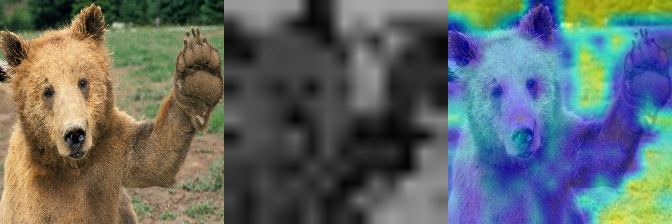

In [3]:
import warnings
warnings.filterwarnings('ignore')
from torchvision import models
import numpy as np
import cv2
import requests
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    deprocess_image, \
    preprocess_image
from PIL import Image

# model = models.resnet50(pretrained=True)
model.eval()
image_url = "https://th.bing.com/th/id/R.94b33a074b9ceeb27b1c7fba0f66db74?rik=wN27mvigyFlXGg&riu=http%3a%2f%2fimages5.fanpop.com%2fimage%2fphotos%2f31400000%2fBear-Wallpaper-bears-31446777-1600-1200.jpg&ehk=oD0JPpRVTZZ6yizZtGQtnsBGK2pAap2xv3sU3A4bIMc%3d&risl=&pid=ImgRaw&r=0"
img = np.array(Image.open(requests.get(image_url, stream=True).raw))
img = cv2.resize(img, (224, 224))
img = np.float32(img) / 255
input_tensor = preprocess_image(img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# The target for the CAM is the Bear category.
# As usual for classication, the target is the logit output
# before softmax, for that category.
targets = [ClassifierOutputTarget(295)]
# target_layers = [model.layer4]
target_layers = [model.blocks[-1].norm1]
with GradCAM(model=model, target_layers=target_layers, reshape_transform=reshape_transform) as cam:
    grayscale_cams = cam(input_tensor=input_tensor, targets=targets, aug_smooth=True, eigen_smooth=True)
    cam_image = show_cam_on_image(img, grayscale_cams[0, :], use_rgb=True)
cam = np.uint8(255*grayscale_cams[0, :])
cam = cv2.merge([cam, cam, cam])
images = np.hstack((np.uint8(255*img), cam , cam_image))
Image.fromarray(images)